<a href="https://colab.research.google.com/github/alex-asf-don/data_analytics/blob/main/Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 2. Кластеризация методом k-means. Сегментация потребителей леденцов.

Выполнена Дон Александром

In [ ]:
from google.colab import files
files.upload()

Saving Леденцы.dat to Леденцы.dat


{'Леденцы.dat': b'V1;V2;V3;V4;V5;V6;V7;V8;V9;V10;V11\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;4;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;4;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;4;3;3;3;3;3;3;3\r\n4;5;5;4;3;3;3;3;3;3;3\r\n5;5;4;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;4;5;4;3;3;3;3;3;3;3\r\n4;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;4;4;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;2;3;3;3\r\n5;4;4;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;4;4;4\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3

**Импорт библиотек**

In [ ]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

**Описание и импорт данных**

Данные содержат оценки степени согласия респондентов с высказываниями, отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:

V1: Я потребляю леденцы, чтобы освежить дыхание

V2: Я потребляю леденцы, чтобы чувствовать себя увереннее

V3: Я потребляю леденцы, чтобы освежить полость рта

V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту

V5: Я потребляю леденцы как заменитель других кондитерских изделий

V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого

V7: Леденцы помогают мне сконцентрироваться

V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать

V9: Я потребляю леденцы для того, чтобы облегчить боль в горле

V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа

V11: Я потребляю леденцы для улучшения самочувствия

In [ ]:
df = pd.read_csv('Леденцы.dat', sep =';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [ ]:
df.shape

(338, 11)

In [ ]:
df.dtypes

,0
V1,int64
V2,int64
V3,int64
V4,int64
V5,int64
V6,int64
V7,int64
V8,int64
V9,int64
V10,int64


In [ ]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Все признаки измеряются по шкале от 2 до 5 баллов, поэтому стандартизация не нужна. Пропуски и выбросы отсутствуют.

**Выбор числа кластеров**

**Построение каменистой осыпи**

В методе k-means необходимо сразу задать число кластеров. Для этого нарисуем график каменистой осыпи.

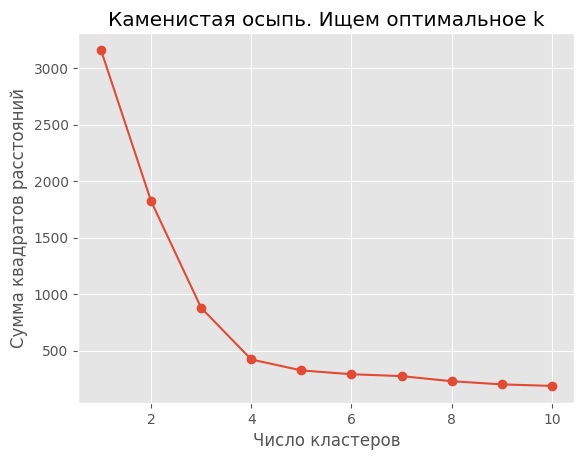

In [ ]:
K = range(1, 11)

models = [KMeans(n_clusters=k, random_state=42).fit(df) for k in K]
dist = [model.inertia_ for model in models]

plt.plot(K, dist, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()

Оптимальное количество кластеров - 4. При переходе от 4 к 3 кластерам происходит резкий скачок в квадратах расстояний между точками данных и их центроидами.

Коэффициент силуэта

Для каждого отдельного объекта i вычисляется 2 показателя:

a(i) - среднее расстояние от объекта i до всех остальных объектов в его собственном кластере.

b(i) - среднее расстояние от объекта i до объектов из ближайшего к нему чужого кластера.

Коэффициент силуэта равен (b−a)/max(a,b). Лежит в диапазоне [-1, 1]:

*   Ближе к 1 - лежит внутри своего кластера и далеко от соседних
*   Ближе к 0 - лежит на границе муежду двумя кластерами
*   Меньше 0 - возможно, попал не в тот кластер



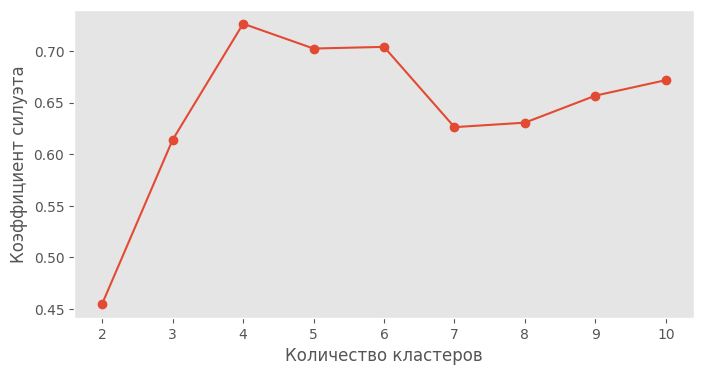

In [ ]:
scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(df)
    scores.append(silhouette_score(df, labels))

# График коэффициента силуэта
plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.xticks(range(2, 11))
plt.grid()
plt.show()

Максимальный коэффициент силуэта: 0.727 при k = 4. Это подтверждает разбиение данных на 4 кластера.

In [ ]:
for k, score in zip(range(2, 11), scores):
    print(k, score)

2 0.45507518357281085
3 0.6140462306588758
4 0.7265095702205504
5 0.7024460026693321
6 0.7040659272839249
7 0.6262461438488439
8 0.630605990194339
9 0.6567886513245842
10 0.6718159935493816


### **Кластеризация методом k-means**

In [ ]:
model = KMeans(n_clusters = 4, random_state = 42, max_iter =100, n_init=10, verbose =0)
labels = model.fit(df)

In [ ]:
print('Число итераций до сходимости:', model.n_iter_)

Число итераций до сходимости: 2


In [ ]:
df['cluster'] = model.labels_
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,cluster
0,4,5,5,5,3,3,3,3,3,3,3,2
1,5,4,5,5,3,3,3,3,3,3,3,2
2,5,5,4,5,3,3,3,3,3,3,3,2
3,5,4,5,5,3,3,3,3,3,3,3,2
4,4,5,5,5,3,3,3,3,3,3,3,2


In [ ]:
df.groupby('cluster').size()

,0
cluster,
0,108
1,61
2,110
3,59


In [ ]:
features = ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11']
X = df[features]
centers = pd.DataFrame(model.cluster_centers_, columns=features)
centers

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
1,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000


In [ ]:
centers = model.cluster_centers_
distances = np.linalg.norm(X - centers[df['cluster'].values], axis=1)
df['dist_to_center'] = distances

density = df.groupby('cluster').agg(Размер = ('dist_to_center', 'size'), Среднее_расстояние = ('dist_to_center', 'mean'))
density.head()

,Размер,Среднее_расстояние
cluster,,
0,108,1.385038
1,61,0.830196
2,110,0.849202
3,59,0.374534


Наиболее однородный и плотный кластер, наименее однородный кластер 0.

**PCA**

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

#Размерность до 2 компонент
pca = PCA(n_components=2)
x = pca.fit_transform(df[features])

centers = pca.transform(model.cluster_centers_)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


**Визуализация**

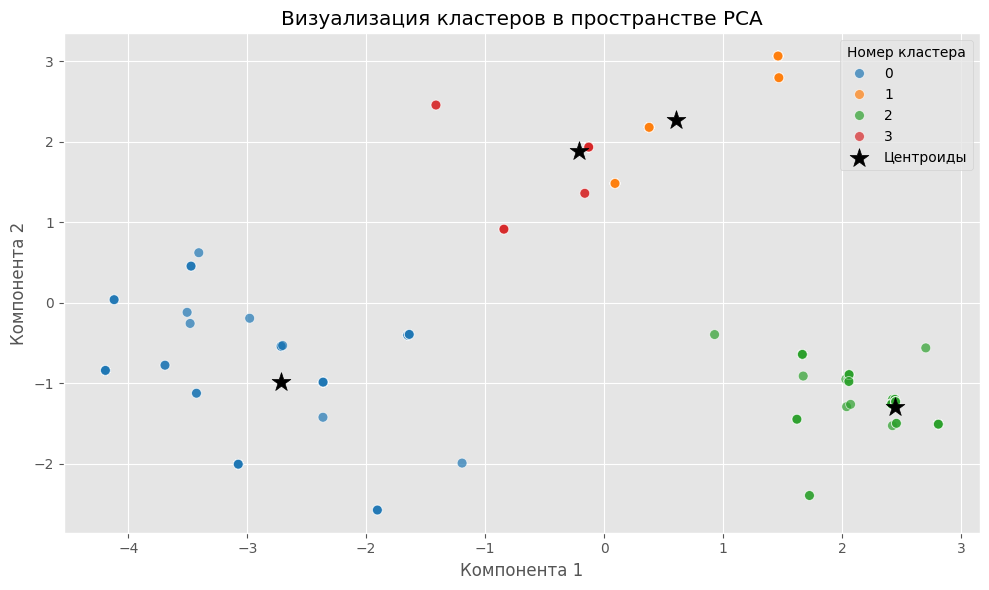

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x[:, 0], y=x[:, 1],
                hue=df['cluster'], palette='tab10',
                s=50, alpha=0.7)

plt.scatter(centers[:, 0], centers[:, 1], marker='*',
            s=200, c='black', label='Центроиды')

plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.title('Визуализация кластеров в пространстве PCA')
plt.legend(title='Номер кластера')
plt.tight_layout()
plt.show()

In [ ]:
print(pca.explained_variance_ratio_[0])
print(pca.explained_variance_ratio_[1])
print(pca.explained_variance_ratio_.sum())

0.4993275103610577
0.28050768853409286
0.7798351988951506


Кластер 1 (108 человек, 32%) - потребители приобретают леденцы для здоровья.

Кластер 2 (110 человек, 32.5%) - потребители приобретают леденцы для уверенности и свежести дыхания в полости рта.

Кластер 3 (59 человек, 17.5%) - потребители приобретают леденцы для концентрации

Кластер 4 (61 человек, 18%) - потребители приобретают ленедцы, так как они им нравятся как сладость

V1: Я потребляю леденцы, чтобы освежить дыхание

V2: Я потребляю леденцы, чтобы чувствовать себя увереннее

V3: Я потребляю леденцы, чтобы освежить полость рта

V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту

V5: Я потребляю леденцы как заменитель других кондитерских изделий

V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого

V7: Леденцы помогают мне сконцентрироваться

V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать

V9: Я потребляю леденцы для того, чтобы облегчить боль в горле

V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа

V11: Я потребляю леденцы для улучшения самочувствия

Вывод:

Покупатели леденцов делятся на 4 кластера.

Больше всего выручки идет от потребителей, которые приобретают леденцы для медицинских целей и дыхания рта. Следовательно, стоит приоритизировать продажу леденцов в аптеках, делать акцент на то, что леденцы помогает от болей в горле и продвигать леденцы с лимонным и мятным вкусом.

17.5% и 18% идут от потребителей, покупающих леденцы для концентрации и от любителей сладкого соответственно. Для первых можно продавать продукт в вендинговых автоматах, рядом с коворкингами в зонах отдыха, а для вторых расширять ассортимент (различные фруктовые, ягодные вкусы).